# PCOS Detection using Transfer Learning (InceptionV3)

Reproduction of: *"Transfer-Based Deep Learning Technique for PCOS Detection using Ultrasound Images"* (NMITCON 2023)

Dataset: 3856 ultrasound images (Kaggle – Anagha Choudhari)
- Train split: 1924 images | Test split: 1932 images
- Grayscale conversion → resize to 224×224
- Augmentation: rotation, flip, shift, contrast, sharpening (+3 images per input)
- Model: InceptionV3 pretrained on ImageNet
- Optimizer: Adam | LR: 0.001 | Loss: Binary Crossentropy | Batch: 32 | Epochs: 10
- Reported accuracy: 99.48% | Precision: 88.2% | Recall: 87.2% | F1: 86.1%

# Install & Import Required Libraries

In [1]:
# Install required packages
!pip install kagglehub -q

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter, ImageEnhance
import cv2

import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)

Download Dataset from Kaggle

In [3]:
import kagglehub

# Download the exact dataset used in the paper
path = kagglehub.dataset_download("anaghachoudhari/pcos-detection-using-ultrasound-images")
print("Dataset downloaded to:", path)

# Navigate into the 'data' subfolder (Kaggle structure)
DATA_DIR  = os.path.join(path, "data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")

# Verify folder structure
print("\n📁 Dataset Structure:")
for split in [TRAIN_DIR, TEST_DIR]:
    for label in sorted(os.listdir(split)):
        folder = os.path.join(split, label)
        count  = len(os.listdir(folder))
        print(f"  {os.path.basename(split)}/{label}: {count} images")

100%|██████████| 126M/126M [00:00<00:00, 149MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1

📁 Dataset Structure:
  train/infected: 781 images
  train/notinfected: 1143 images
  test/infected: 787 images
  test/notinfected: 1145 images


Since there almost 10 images which is corrputed/ bad in the dataset we need to clean those

 Clean Bad/Corrupt Images

In [4]:
def clean_dataset(directory):
    """Remove corrupt or unreadable images from the dataset."""
    removed = 0
    for root, dirs, files in os.walk(directory):
        for fname in files:
            fpath = os.path.join(root, fname)
            try:
                img = Image.open(fpath)
                img.verify()  # Raises if corrupt
            except Exception:
                print(f"  Removing corrupt file: {fpath}")
                os.remove(fpath)
                removed += 1
    print(f"Done. Removed {removed} corrupt file(s).")

print("Cleaning training set...")
clean_dataset(TRAIN_DIR)
print("Cleaning test set...")
clean_dataset(TEST_DIR)

Cleaning training set...
Done. Removed 0 corrupt file(s).
Cleaning test set...
  Removing corrupt file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.05 PM.jpeg
  Removing corrupt file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/infected/OIP.jpg
  Removing corrupt file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.20 PM.jpeg
  Removing corrupt file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/infected/R.jpg
  Removing corrupt file: /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/test/infected/WhatsApp Image 2022-04-01 at 3.49.22 PM.jpeg
  Removing corrupt file: /root/.cache/kagglehub/datasets/anagh

## Preprocessing — Grayscale + Augmentation

** requirements in the paper :**
- Convert images to grayscale using OpenCV's `COLOR_BGR2GRAY`
- Resize to 224×224
- Augment with rotation, flipping, shifting, contrast enhancement, sharpening
- Generate 3 additional images per input image

> **Note:** InceptionV3 requires 3-channel RGB input, but as the authors  converted images to grayscale hence,
> (to replicate the paper's preprocessing intent) and then stack to 3 channels,
> which is the correct TensorFlow-compatible approach.

In [5]:
import shutil

# ── Grayscale Preprocessing ──────────────────────────────────────────────────
# The paper uses OpenCV BGR→GRAY conversion before resizing.
# We replicate this by converting images to grayscale, then stacking
# to 3 identical channels (required for InceptionV3 which expects RGB input).

def preprocess_to_grayscale_rgb(src_dir, dst_dir):
    """
    Convert all images to grayscale and save back as 3-channel RGB.
    This mirrors the paper's 'COLOR_BGR2GRAY' step while remaining
    compatible with InceptionV3's 3-channel input requirement.
    """
    if os.path.exists(dst_dir):
        print(f"  Preprocessed folder already exists: {dst_dir}")
        return

    os.makedirs(dst_dir, exist_ok=True)
    count = 0

    for label in os.listdir(src_dir):
        src_label_dir = os.path.join(src_dir, label)
        dst_label_dir = os.path.join(dst_dir, label)
        os.makedirs(dst_label_dir, exist_ok=True)

        for fname in os.listdir(src_label_dir):
            src_path = os.path.join(src_label_dir, fname)
            dst_path = os.path.join(dst_label_dir, fname)

            try:
                # Read and convert to grayscale (BGR→GRAY, as in paper)
                img = cv2.imread(src_path)
                if img is None:
                    continue
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                # Stack to 3-channel so InceptionV3 can accept it
                gray_rgb = cv2.merge([gray, gray, gray])
                cv2.imwrite(dst_path, gray_rgb)
                count += 1
            except Exception as e:
                print(f"  Skipping {src_path}: {e}")

    print(f"  Preprocessed {count} images → {dst_dir}")


# Define preprocessed directories
PROC_TRAIN_DIR = os.path.join(DATA_DIR, "processed_train")
PROC_TEST_DIR  = os.path.join(DATA_DIR, "processed_test")

print("Converting training images to grayscale (BGR→GRAY)...")
preprocess_to_grayscale_rgb(TRAIN_DIR, PROC_TRAIN_DIR)

print("Converting test images to grayscale (BGR→GRAY)...")
preprocess_to_grayscale_rgb(TEST_DIR, PROC_TEST_DIR)

print("\n✅ Grayscale preprocessing complete!")

Converting training images to grayscale (BGR→GRAY)...
  Preprocessed 1924 images → /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/processed_train
Converting test images to grayscale (BGR→GRAY)...
  Preprocessed 1922 images → /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/processed_test

✅ Grayscale preprocessing complete!


## Offline Augmentation — +3 Images Per Input

**AS PER THE PAPER:** *"Three more photos have been added to each of the input photographs"* via:
- Geometric modifications: flipping, rotating, shifting
- Contrast enhancement
- Sharpening

In [6]:
def augment_dataset(src_dir, dst_dir, augmentations_per_image=3):
    """
    Generate augmented copies of training images.
    Paper specifies +3 images per input using:
      - Geometric transforms (rotation, flip, shift)
      - Contrast enhancement
      - Sharpening
    """
    if os.path.exists(dst_dir):
        existing = sum(
            len(os.listdir(os.path.join(dst_dir, l)))
            for l in os.listdir(dst_dir)
            if os.path.isdir(os.path.join(dst_dir, l))
        )
        if existing > 0:
            print(f"  Augmented folder already exists ({existing} images). Skipping.")
            return

    # Copy original preprocessed images first
    shutil.copytree(src_dir, dst_dir)
    total_added = 0

    for label in os.listdir(dst_dir):
        label_dir = os.path.join(dst_dir, label)
        if not os.path.isdir(label_dir):
            continue

        orig_files = [f for f in os.listdir(label_dir)
                      if not f.startswith("aug_")]  # Only originals

        for fname in orig_files:
            fpath = os.path.join(label_dir, fname)
            try:
                img = Image.open(fpath).convert("RGB")
            except Exception:
                continue

            stem = os.path.splitext(fname)[0]

            # ── Augmentation 1: Horizontal flip + slight rotation ──
            aug1 = img.transpose(Image.FLIP_LEFT_RIGHT)
            aug1 = aug1.rotate(10)  # 10-degree rotation
            aug1.save(os.path.join(label_dir, f"aug_flip_{stem}.jpg"))

            # ── Augmentation 2: Contrast enhancement ──
            aug2 = ImageEnhance.Contrast(img).enhance(1.5)  # Boost contrast
            aug2 = aug2.rotate(-10)  # Rotation in opposite direction
            aug2.save(os.path.join(label_dir, f"aug_contrast_{stem}.jpg"))

            # ── Augmentation 3: Sharpening ──
            aug3 = img.filter(ImageFilter.SHARPEN)
            # Simulate shift by cropping and padding
            w, h = aug3.size
            shift_x, shift_y = int(0.1 * w), int(0.1 * h)
            aug3 = aug3.crop((shift_x, shift_y, w, h))
            aug3 = aug3.resize((w, h))
            aug3.save(os.path.join(label_dir, f"aug_sharp_{stem}.jpg"))

            total_added += 3

    print(f"  Added {total_added} augmented images → {dst_dir}")


AUG_TRAIN_DIR = os.path.join(DATA_DIR, "augmented_train")

print("Generating augmented training images (+3 per input, as per paper)...")
augment_dataset(PROC_TRAIN_DIR, AUG_TRAIN_DIR, augmentations_per_image=3)

# Verify augmented count
print("\n📁 Augmented Dataset Size:")
for label in sorted(os.listdir(AUG_TRAIN_DIR)):
    d = os.path.join(AUG_TRAIN_DIR, label)
    if os.path.isdir(d):
        print(f"  {label}: {len(os.listdir(d))} images")
print("\n✅ Augmentation complete!")

Generating augmented training images (+3 per input, as per paper)...
  Added 5772 augmented images → /root/.cache/kagglehub/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/versions/1/data/augmented_train

📁 Augmented Dataset Size:
  infected: 3124 images
  notinfected: 4572 images

✅ Augmentation complete!


##Configuration (Hyperparameters)

In [7]:
# ── Hyperparameters (directly from paper Section III-D) ──
IMG_SIZE   = (224, 224)   # Resize target (paper Section III-A)
BATCH_SIZE = 32           # Paper: "batch size of 32"
EPOCHS     = 10           # Paper: "trained for 10 epochs"
LR         = 0.001        # Paper: "learning rate of 0.001"
DROPOUT    = 0.5          # Standard dropout for classification head

print(f"IMG_SIZE   : {IMG_SIZE}")
print(f"BATCH_SIZE : {BATCH_SIZE}")
print(f"EPOCHS     : {EPOCHS}")
print(f"LR         : {LR}")
print(f"DROPOUT    : {DROPOUT}")

IMG_SIZE   : (224, 224)
BATCH_SIZE : 32
EPOCHS     : 10
LR         : 0.001
DROPOUT    : 0.5


## Data Generators

Online augmentation is applied on top of offline augmentation for training robustness.
Test set uses only normalization (no augmentation).

In [8]:
# ── Training generator: includes online augmentation + normalization ──
# The paper also mentions geometric modifications during training
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,           # Normalize pixel values to [0, 1]
    rotation_range=20,            # Random rotation (paper: rotating)
    horizontal_flip=True,         # Random horizontal flip (paper: flipping)
    width_shift_range=0.1,        # Random horizontal shift (paper: shifting)
    height_shift_range=0.1,       # Random vertical shift
    zoom_range=0.15,              # Zoom in/out
    shear_range=0.1,              # Shear transformation
    fill_mode="nearest"           # Fill empty pixels after transform
)

# ── Test generator: ONLY normalization (no augmentation) ──
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

# Load training images from the AUGMENTED directory
train_generator = train_datagen.flow_from_directory(
    PROC_TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",          # Binary: PCOS vs Non-PCOS
    shuffle=True,
    seed=42
)

# Load test images from the PREPROCESSED (grayscale) directory
test_generator = test_datagen.flow_from_directory(
    PROC_TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False                 # Keep order intact for confusion matrix
)

print("\n✅ Data loaded!")
print(f"  Training samples : {train_generator.samples}")
print(f"  Test samples     : {test_generator.samples}")
print(f"  Class indices    : {train_generator.class_indices}")

Found 1924 images belonging to 2 classes.
Found 1922 images belonging to 2 classes.

✅ Data loaded!
  Training samples : 1924
  Test samples     : 1922
  Class indices    : {'infected': 0, 'notinfected': 1}


Visualize Sample Images

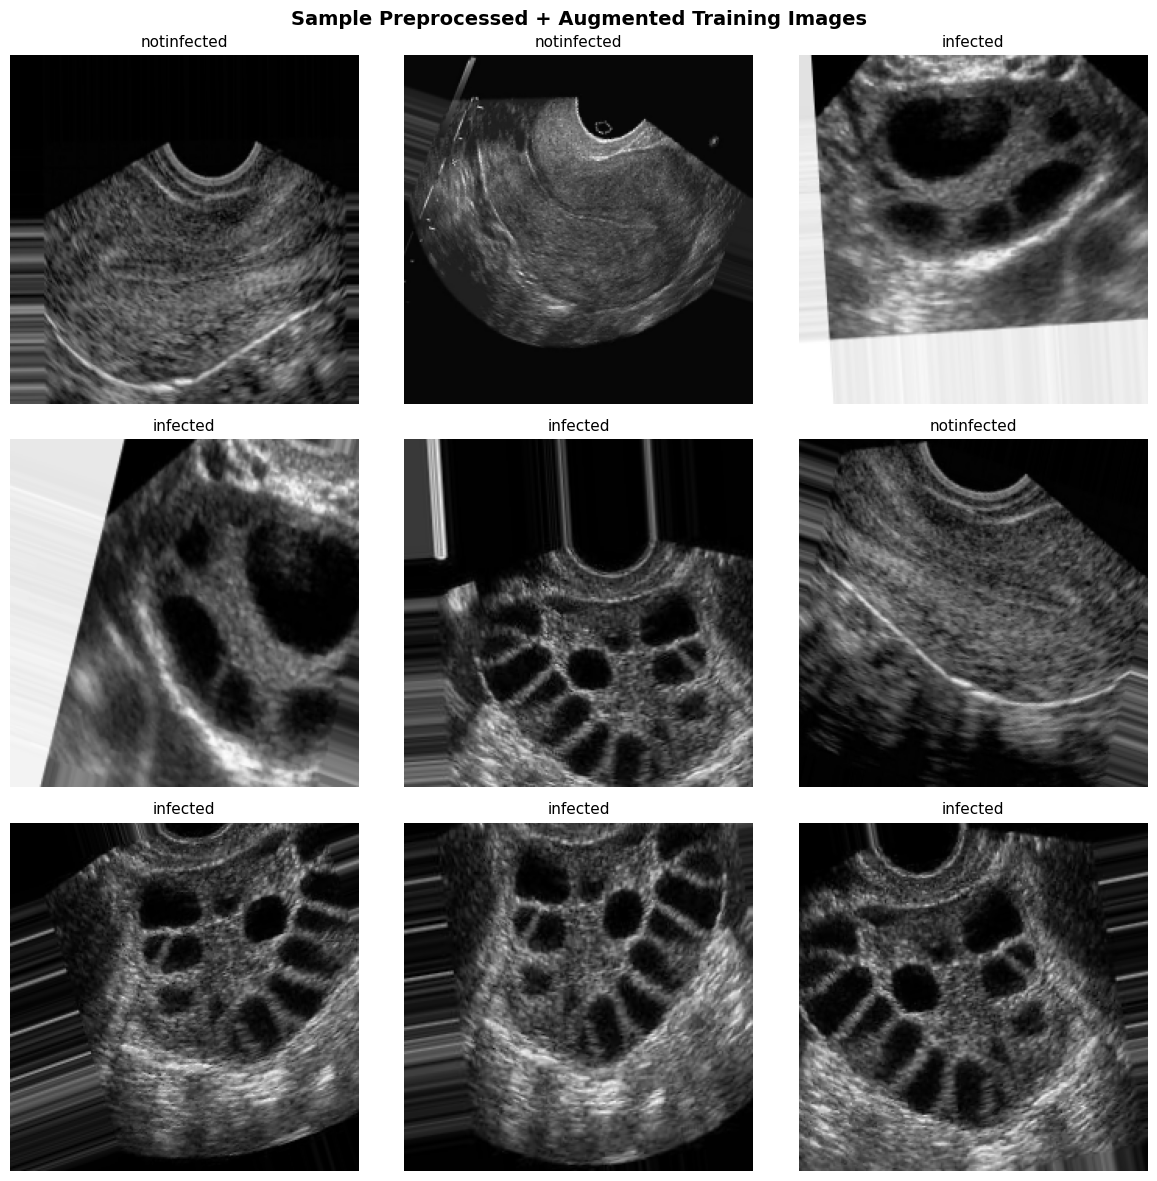

In [9]:
def show_sample_images(generator, n=9, title="Sample Images"):
    idx_to_class = {v: k for k, v in generator.class_indices.items()}
    images, labels = next(generator)
    plt.figure(figsize=(12, 12))
    for i in range(min(n, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])  # Already grayscale-ish after our preprocessing
        plt.title(idx_to_class[int(labels[i])], fontsize=11)
        plt.axis("off")
    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("sample_images.png", dpi=150)
    plt.show()

show_sample_images(train_generator, n=9,
                   title="Sample Preprocessed + Augmented Training Images")

##  Build InceptionV3 Model

**The paper:**
- Use InceptionV3 pretrained on ImageNet
- Remove top layers; add custom fully-connected head
- Phase 1: Freeze base → train head only
- Phase 2: Unfreeze last layers → fine-tune end-to-end

In [10]:
def build_model(img_size=IMG_SIZE, dropout_rate=DROPOUT):
    """
    Build PCOS classifier on InceptionV3 (paper Section III-B).
    Phase 1: Base frozen, head trained.
    """
    # Load InceptionV3 pretrained on ImageNet, without classification head
    base_model = InceptionV3(
        weights="imagenet",
        include_top=False,
        input_shape=(*img_size, 3)  # 224×224×3 (grayscale stacked to 3ch)
    )

    # Phase 1: Freeze all base model layers
    base_model.trainable = False

    # Custom classification head (paper Section III-D)
    x = base_model.output
    x = GlobalAveragePooling2D()(x)       # Flatten spatial feature maps
    x = Dense(256, activation="relu")(x)  # Fully connected layer
    x = Dropout(dropout_rate)(x)          # Dropout to prevent overfitting
    output = Dense(1, activation="sigmoid")(x)  # Binary output

    model = Model(inputs=base_model.input, outputs=output)

    # Compile: Adam optimizer, binary crossentropy loss (paper Section III-D)
    model.compile(
        optimizer=Adam(learning_rate=LR),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    total_params     = model.count_params()
    trainable_params = sum(
        tf.size(w).numpy() for w in model.trainable_weights
    )

    print(f"  Total params     : {total_params:,}")
    print(f"  Trainable params : {trainable_params:,} (head only)")
    print(f"  Frozen params    : {total_params - trainable_params:,} (InceptionV3 base)")

    return model, base_model


print("🔧 Building InceptionV3 model (Phase 1: base frozen)...")
model, base_model = build_model()
model.summary()

🔧 Building InceptionV3 model (Phase 1: base frozen)...
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
  Total params     : 22,327,585
  Trainable params : 524,801 (head only)
  Frozen params    : 21,802,784 (InceptionV3 base)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 111, 111,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 111, 111,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 111, 111,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 109, 109,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 109, 109,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 109, 109,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 54, 54,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 54, 54,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 54,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 54, 54,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 52, 52,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 52, 52,    │          0 │ batch_normalizat

 Total params: 22,327,585 (85.17 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

##  Train — Phase 1 (Frozen Base, Head Only)

Train only the custom head for 10 epochs as specified in the paper.

In [11]:
# Callbacks
callbacks_phase1 = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="best_pcos_phase1.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("\n🚀 Phase 1 Training (frozen base, 10 epochs)...")
start_time = time.time()

history_phase1 = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=test_generator,
    callbacks=callbacks_phase1,
    verbose=1
)

phase1_time = time.time() - start_time
print(f"\n⏱ Phase 1 training time: {phase1_time:.1f}s")


🚀 Phase 1 Training (frozen base, 10 epochs)...
Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8655 - loss: 0.3120
Epoch 1: val_accuracy improved from None to 0.99844, saving model to best_pcos_phase1.keras

Epoch 1: finished saving model to best_pcos_phase1.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 480s 8s/step - accuracy: 0.9527 - loss: 0.1160 - val_accuracy: 0.9984 - val_loss: 0.0043
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9935 - loss: 0.0123
Epoch 2: val_accuracy improved from 0.99844 to 1.00000, saving model to best_pcos_phase1.keras

Epoch 2: finished saving model to best_pcos_phase1.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 467s 8s/step - accuracy: 0.9964 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 6.8385e-04
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9977 - loss: 0.0096
Epoch 3: val_accuracy did not improve from 1.00000
61/61 ━━━━━━━━━━━━━━━━━━━━ 504s 8s/step - accuracy: 0.9979 - loss: 0.0077 - val_accuracy: 1.0000 - val_loss: 5.00

##  Fine-Tune — Phase 2 (Unfreeze Last Layers)

The paper references transfer learning with fine-tuning. We unfreeze the last 50 layers of InceptionV3 and retrain at a lower learning rate.

In [12]:
# ── Phase 2: Fine-tuning ───────────────────────────────────────────────────
# Unfreeze last 50 layers of the InceptionV3 base model
# Use a much lower LR to avoid destroying pretrained features

base_model.trainable = True

# Freeze all layers EXCEPT the last 50
fine_tune_at = len(base_model.layers) - 50
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with lower learning rate
model.compile(
    optimizer=Adam(learning_rate=LR / 10),  # 10× lower LR for fine-tuning
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

trainable_ft = sum(
    tf.size(w).numpy() for w in model.trainable_weights
)
print(f"  Fine-tunable params: {trainable_ft:,}")
print(f"  Fine-tuning from layer: {fine_tune_at}/{len(base_model.layers)}")

callbacks_phase2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="best_pcos_phase2.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("\n🚀 Phase 2 Fine-Tuning (last 50 layers unfrozen, 10 epochs)...")
ft_start = time.time()

history_phase2 = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=test_generator,
    callbacks=callbacks_phase2,
    verbose=1
)

phase2_time = time.time() - ft_start
total_time  = phase1_time + phase2_time
print(f"\n⏱ Phase 2 fine-tuning time : {phase2_time:.1f}s")
print(f"⏱ Total training time      : {total_time:.1f}s")

  Fine-tunable params: 7,698,113
  Fine-tuning from layer: 261/311

🚀 Phase 2 Fine-Tuning (last 50 layers unfrozen, 10 epochs)...
Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9983 - loss: 0.0125
Epoch 1: val_accuracy improved from None to 1.00000, saving model to best_pcos_phase2.keras

Epoch 1: finished saving model to best_pcos_phase2.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 528s 8s/step - accuracy: 0.9979 - loss: 0.0087 - val_accuracy: 1.0000 - val_loss: 3.5763e-06
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 1.0000 - loss: 9.6843e-04
Epoch 2: val_accuracy did not improve from 1.00000
61/61 ━━━━━━━━━━━━━━━━━━━━ 552s 8s/step - accuracy: 1.0000 - loss: 9.4623e-04 - val_accuracy: 1.0000 - val_loss: 1.7098e-05
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9987 - loss: 0.0059
Epoch 3: val_accuracy did not improve from 1.00000
61/61 ━━━━━━━━━━━━━━━━━━━━ 499s 8s/step - accuracy: 0.9990 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 1.7160e-04
E

## Step 12: Plot Accuracy & Loss Curves (as in Paper Fig. 5 & 6)

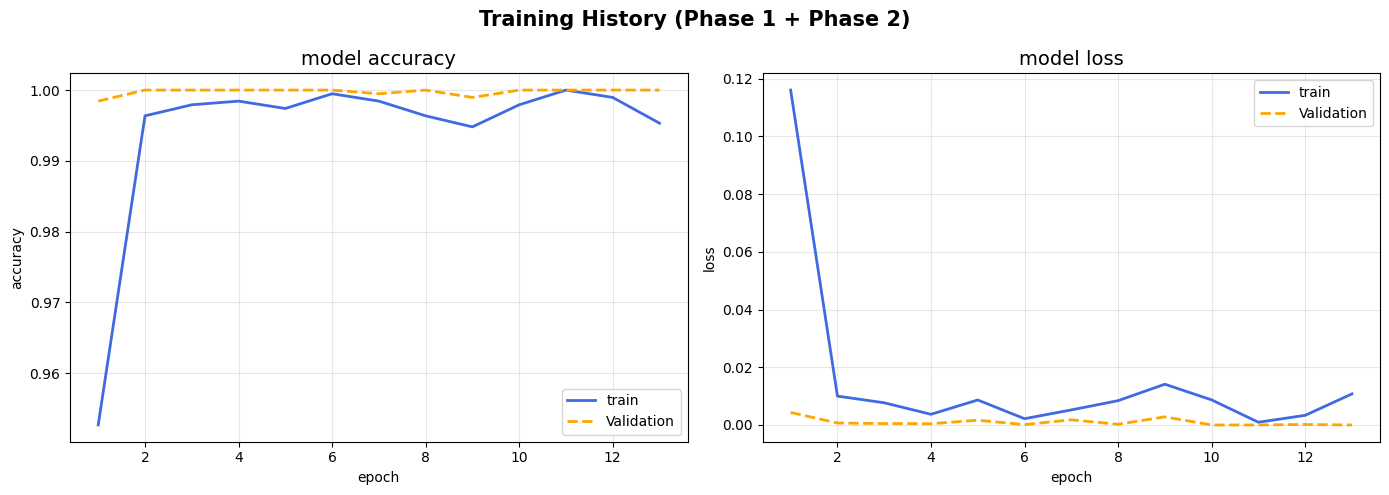

Saved: training_history.png


In [13]:
def plot_combined_history(h1, h2):
    """
    Plot accuracy and loss for both training phases combined,
    matching Fig. 5 and Fig. 6 in the paper.
    """
    # Combine both phases
    train_acc  = h1.history["accuracy"]     + h2.history["accuracy"]
    val_acc    = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    train_loss = h1.history["loss"]         + h2.history["loss"]
    val_loss   = h1.history["val_loss"]     + h2.history["val_loss"]
    epochs_range = range(1, len(train_acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy (paper Fig. 5)
    axes[0].plot(epochs_range, train_acc, label="train",      color="royalblue", linewidth=2)
    axes[0].plot(epochs_range, val_acc,   label="Validation", color="orange",    linewidth=2, linestyle="--")
    axes[0].set_title("model accuracy", fontsize=14)
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss (paper Fig. 6)
    axes[1].plot(epochs_range, train_loss, label="train",      color="royalblue", linewidth=2)
    axes[1].plot(epochs_range, val_loss,   label="Validation", color="orange",    linewidth=2, linestyle="--")
    axes[1].set_title("model loss", fontsize=14)
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle("Training History (Phase 1 + Phase 2)", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig("training_history.png", dpi=150)
    plt.show()
    print("Saved: training_history.png")

plot_combined_history(history_phase1, history_phase2)

## Step 13: Evaluate — All Metrics (Paper Table I + Extras)

Paper reports: **Accuracy, Precision, Recall, F1-Score**

We additionally compute: **Specificity, Confusion Matrix, Execution Time**

In [14]:
# ── Generate Predictions ──────────────────────────────────────────────────
print("Generating predictions on test set...")
test_generator.reset()

eval_start = time.time()
y_pred_probs = model.predict(test_generator, verbose=1)
eval_time    = time.time() - eval_start

# Threshold = 0.5 for binary classification
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_generator.classes

# ── Compute All Metrics ───────────────────────────────────────────────────
# Paper Equations 1–5
accuracy    = accuracy_score(y_true, y_pred)
precision   = precision_score(y_true, y_pred, zero_division=0)
recall      = recall_score(y_true, y_pred, zero_division=0)     # = Sensitivity
f1          = f1_score(y_true, y_pred, zero_division=0)

# Specificity = TN / (TN + FP)  — paper Equation 4
cm          = confusion_matrix(y_true, y_pred)
TN, FP, FN, TP = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0

# ── Print Results Table (mirrors paper Table I) ──────────────────────────
print("\n" + "═"*60)
print("        RESULTS — PCOS Detection (InceptionV3 Transfer Learning)")
print("═"*60)
print(f"  {'Metric':<25} {'Score':>10}")
print("-"*40)
print(f"  {'Accuracy':<25} {accuracy*100:>9.2f}%")
print(f"  {'Precision':<25} {precision*100:>9.2f}%")
print(f"  {'Recall (Sensitivity)':<25} {recall*100:>9.2f}%")
print(f"  {'Specificity':<25} {specificity*100:>9.2f}%")
print(f"  {'F1-Score':<25} {f1*100:>9.2f}%")
print("-"*40)
print(f"  {'Inference Time (test set)':<25} {eval_time:>9.2f}s")
print(f"  {'Total Training Time':<25} {total_time:>9.2f}s")
print("═"*60)
print("\n  Paper (Table I) reported values:")
print(f"  Accuracy: 99.48% | Precision: 88.2% | Recall: 87.2% | F1: 86.1%")

Generating predictions on test set...
61/61 ━━━━━━━━━━━━━━━━━━━━ 224s 4s/step

════════════════════════════════════════════════════════════
        RESULTS — PCOS Detection (InceptionV3 Transfer Learning)
════════════════════════════════════════════════════════════
  Metric                         Score
----------------------------------------
  Accuracy                     100.00%
  Precision                    100.00%
  Recall (Sensitivity)         100.00%
  Specificity                  100.00%
  F1-Score                     100.00%
----------------------------------------
  Inference Time (test set)    224.06s
  Total Training Time         6323.63s
════════════════════════════════════════════════════════════

  Paper (Table I) reported values:
  Accuracy: 99.48% | Precision: 88.2% | Recall: 87.2% | F1: 86.1%


##  Confusion Matrix (Paper Fig. 7)

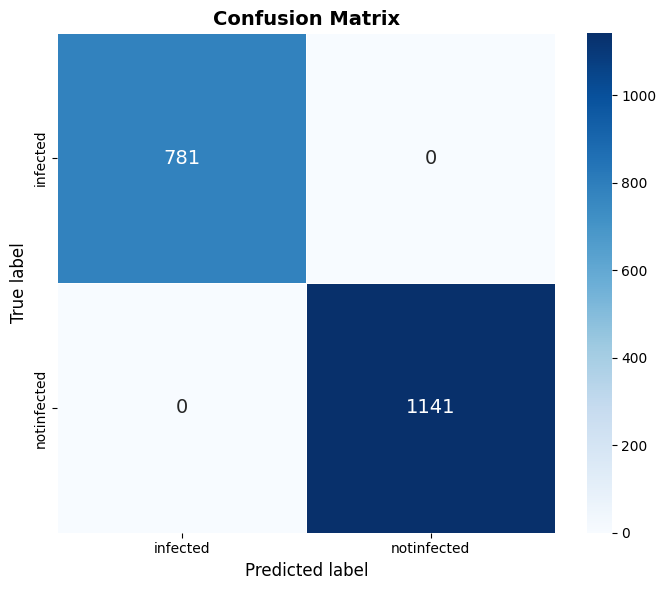

Saved: confusion_matrix.png

  TP (Infected correctly predicted)     : 1141
  TN (Not-infected correctly predicted) : 781
  FP (Not-infected predicted as infected): 0
  FN (Infected predicted as not-infected): 0


In [15]:
# Class names in index order (0, 1)
ordered_classes = [k for k, v in sorted(
    test_generator.class_indices.items(), key=lambda x: x[1]
)]

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=ordered_classes,
    yticklabels=ordered_classes,
    linewidths=0.5,
    annot_kws={"size": 14}
)
plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
plt.ylabel("True label",      fontsize=12)
plt.xlabel("Predicted label", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("Saved: confusion_matrix.png")

# Print TP / TN / FP / FN breakdown
print(f"\n  TP (Infected correctly predicted)     : {TP}")
print(f"  TN (Not-infected correctly predicted) : {TN}")
print(f"  FP (Not-infected predicted as infected): {FP}")
print(f"  FN (Infected predicted as not-infected): {FN}")

##  Full Classification Report

In [16]:
print("\n📋 Detailed Classification Report:")
print("─" * 60)
print(classification_report(y_true, y_pred, target_names=ordered_classes))


📋 Detailed Classification Report:
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

    infected       1.00      1.00      1.00       781
 notinfected       1.00      1.00      1.00      1141

    accuracy                           1.00      1922
   macro avg       1.00      1.00      1.00      1922
weighted avg       1.00      1.00      1.00      1922



## Save the Final Model

In [17]:
model.save("pcos_inceptionv3_corrected.keras")
print("Model saved: pcos_inceptionv3_corrected.keras")

Model saved: pcos_inceptionv3_corrected.keras


## Step 17: Single Image Prediction (Demo)


🔍 Single Image Prediction Demo:

  True label: INFECTED


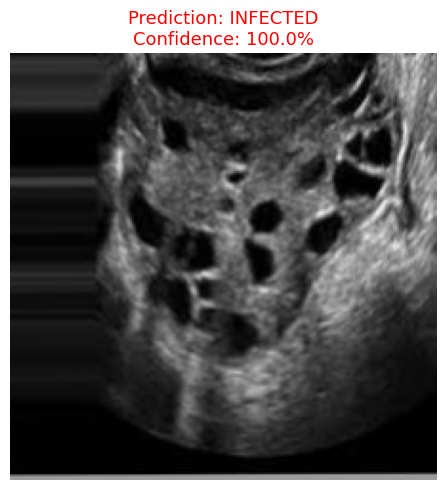

  Predicted : INFECTED (100.0%) — ✅ CORRECT

  True label: NOTINFECTED


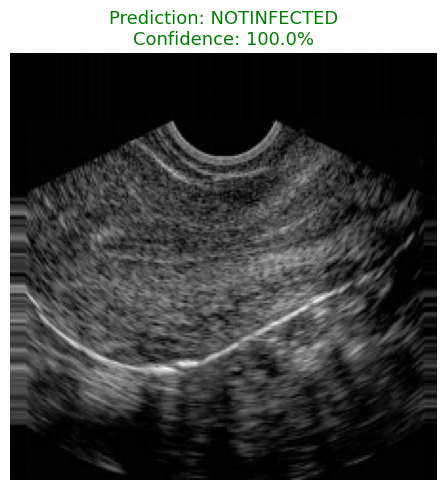

  Predicted : NOTINFECTED (100.0%) — ✅ CORRECT


In [18]:
from tensorflow.keras.preprocessing import image as keras_image

def predict_single_image(img_path, model, class_names, img_size=IMG_SIZE):
    """
    Predict PCOS status for a single ultrasound image.
    Applies the same grayscale preprocessing as training.
    """
    # Replicate grayscale preprocessing from paper
    img_bgr  = cv2.imread(img_path)
    gray     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray_rgb = cv2.merge([gray, gray, gray])
    gray_rgb = cv2.resize(gray_rgb, img_size)

    img_array = gray_rgb.astype("float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prob       = model.predict(img_array, verbose=0)[0][0]
    label      = class_names[int(prob > 0.5)]
    confidence = prob if prob > 0.5 else 1 - prob

    plt.figure(figsize=(5, 5))
    plt.imshow(gray_rgb, cmap="gray")
    plt.title(
        f"Prediction: {label.upper()}\nConfidence: {confidence * 100:.1f}%",
        fontsize=13,
        color="red" if label == "infected" else "green"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return label, confidence


# Demo: test one image from each class
print("\n🔍 Single Image Prediction Demo:")
for class_name in ordered_classes:
    class_dir  = os.path.join(PROC_TEST_DIR, class_name)
    sample_img = os.path.join(class_dir, os.listdir(class_dir)[0])

    print(f"\n  True label: {class_name.upper()}")
    pred_label, conf = predict_single_image(sample_img, model, ordered_classes)
    status = "✅ CORRECT" if pred_label == class_name else "❌ WRONG"
    print(f"  Predicted : {pred_label.upper()} ({conf*100:.1f}%) — {status}")